# HI Spectrum Stacking — Function Module

This notebook defines a single function, `stack_hi_spectrum`, that wraps
the entire pipeline: selecting survey pixels near a target sky position
with a Gaussian beam, stacking their spectra from the TAN FITS cubes,
and (optionally) plotting the result against a comparison spectrum.

Run this notebook once to define the function (or `%run` it / import it
from another notebook), then call `stack_hi_spectrum(...)` with your own
parameters — see the example call at the bottom.


## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from pathlib import Path


## Function definition

In [2]:
def stack_hi_spectrum(
    target_ra,
    target_dec,
    beam_fwhm_deg,
    strips_table_path="all_ra_strips2.fits",
    tan_dir="/home/edgeflame/Documents/internshiph1/TAN",
    min_weight=1e-5,
    comparison_velocity=None,
    comparison_intensity=None,
    comparison_label="Comparison Data",
    plot=True,
    xlim=None,
):
    """
    Build a Gaussian-weighted, stacked HI spectrum for a target sky
    position from a set of TAN_*.fits data cubes, and optionally plot
    it alongside a comparison spectrum.

    How it works
    ------------
    1. A Gaussian beam of the given FWHM is centered on (target_ra,
       target_dec). An angular cutoff radius is derived from
       `min_weight`: pixels whose Gaussian weight would fall below
       this threshold are excluded.
    2. Every pixel listed in `strips_table_path` within that angular
       cutoff of the target is assigned a Gaussian weight based on its
       angular separation from the target.
    3. For each FITS cube that contributes at least one selected
       pixel, the corresponding spectra are extracted, weighted, and
       summed into a single running total, normalized by the total
       weight across all selected pixels.
    4. The resulting stacked spectrum is returned (and optionally
       plotted against a comparison spectrum).

    Parameters
    ----------
    target_ra : float
        Target Right Ascension, in degrees. Center of the Gaussian
        beam used to select and weight nearby pixels.
    target_dec : float
        Target Declination, in degrees. Center of the Gaussian beam
        used to select and weight nearby pixels.
    beam_fwhm_deg : float
        Full width at half maximum (FWHM) of the telescope beam, in
        degrees. Determines the width of the Gaussian weighting
        function and, together with `min_weight`, the angular search
        radius around the target.
    strips_table_path : str or Path, optional
        Path to the FITS table containing per-pixel survey data.
        Must have columns "ra", "dec", "file", "row", "col" (degrees
        for ra/dec; "file" gives the cube filename each pixel belongs
        to; "row"/"col" give that pixel's index within the cube).
        Defaults to "all_ra_strips2.fits" in the current directory.
    tan_dir : str or Path, optional
        Directory containing the TAN_*.fits data cubes referenced by
        the "file" column of `strips_table_path`. Defaults to
        "/home/edgeflame/Documents/internshiph1/TAN". 
    min_weight : float, optional
        Minimum Gaussian weight (relative to peak) for a pixel to
        still be included. Smaller values widen the search radius
        around the target. Defaults to 1e-5.
    comparison_velocity : array-like, optional
        Velocity axis (in m/s) for an external comparison spectrum
        (e.g. a radio telescope observation or catalog spectrum) to
        plot alongside the computed stacked spectrum. Must be the
        same length as `comparison_intensity`. If None, no comparison
        spectrum is plotted.
    comparison_intensity : array-like, optional
        Intensity/temperature values (in K) for the comparison
        spectrum, paired with `comparison_velocity`. Must be the same
        length as `comparison_velocity`. If None, no comparison
        spectrum is plotted.
    comparison_label : str, optional
        Legend label for the comparison spectrum, if provided.
        Defaults to "Comparison Data".
    plot : bool, optional
        If True (default), generate a matplotlib plot of the stacked
        spectrum (and comparison spectrum, if provided). Set to False
        to skip plotting and only get the returned arrays.
    xlim : tuple of (float, float), optional
        If given, passed to `plt.xlim(*xlim)` to set the x-axis range
        of the plot (e.g. `(-70000, 170000)`). Only used if `plot`
        is True.

    Returns
    -------
    velocity : numpy.ndarray
        Velocity axis (in m/s) of the stacked spectrum, built from the
        WCS of the first contributing FITS cube.
    weighted_spectrum : numpy.ndarray
        The Gaussian-weighted, stacked HI spectrum corresponding to
        `velocity`.
    n_pixels : int
        The number of survey pixels that fell within the angular
        cutoff and contributed to the stack.
    """

    tan_dir = Path(tan_dir)

    # ------------------------------------------------------------
    # 1. Gaussian beam parameters and angular cutoff
    # ------------------------------------------------------------
    # Convert FWHM (deg) to a Gaussian sigma (radians).
    sigma = np.deg2rad(beam_fwhm_deg) / np.sqrt(8 * np.log(2))
    mean = 0  # Gaussian is centered on zero angular distance from target

    # Work in degrees to compute the angular cutoff radius: the
    # radius at which the Gaussian weight drops to min_weight.
    sigma_deg = np.rad2deg(sigma)
    norm = 1 / (sigma_deg * np.sqrt(2 * np.pi))
    angular_cutoff = sigma_deg * np.sqrt(
        2 * (np.log(norm) - np.log(min_weight))
    )

    # ------------------------------------------------------------
    # 2. Load survey pixel table and compute per-pixel Gaussian weights
    # ------------------------------------------------------------
    data = Table.read(strips_table_path)

    all_ra = np.asarray(data["ra"])
    all_dec = np.asarray(data["dec"])

    ra = np.deg2rad(all_ra)
    dec = np.deg2rad(all_dec)

    # Target position in radians (beam center).
    ra0 = np.deg2rad(target_ra)
    dec0 = np.deg2rad(target_dec)

    # Unit vector for the target direction.
    xt = np.cos(dec0) * np.cos(ra0)
    yt = np.cos(dec0) * np.sin(ra0)
    zt = np.sin(dec0)

    # Unit vectors for every survey pixel.
    xp = np.cos(dec) * np.cos(ra)
    yp = np.cos(dec) * np.sin(ra)
    zp = np.sin(dec)

    # Angular separation between each pixel and the target, via the
    # dot product of unit vectors (clipped to avoid arccos issues).
    dot = xp * xt + yp * yt + zp * zt
    dot = np.clip(dot, -1.0, 1.0)
    distance = np.arccos(dot)  # radians

    cutoff = np.deg2rad(angular_cutoff)

    # Gaussian weight for every pixel; zero outside the angular cutoff.
    weights = np.zeros_like(distance)
    mask = distance <= cutoff
    weights[mask] = np.exp(
        -((distance[mask] - mean) ** 2) / (2 * sigma ** 2)
    )

    weights_sum = np.sum(weights)
    n_pixels = int(np.count_nonzero(mask))

    # Boolean mask selecting every pixel with a nonzero weight.
    plot_mask = weights > 0

    # ------------------------------------------------------------
    # 3. Subselect file/row/col bookkeeping for pixels inside the beam
    # ------------------------------------------------------------
    table = Table.read(strips_table_path)

    all_files = np.asarray(table["file"]).astype(str)
    all_rows = np.asarray(table["row"])
    all_cols = np.asarray(table["col"])

    plot_files = all_files[plot_mask]
    plot_rows = all_rows[plot_mask]
    plot_cols = all_cols[plot_mask]
    plot_weights = weights[plot_mask]

    # ------------------------------------------------------------
    # 4. Build the weighted, stacked spectrum
    # ------------------------------------------------------------
    weighted_spectrum = None
    velocity = None

    for filename in np.unique(plot_files):

        path = tan_dir / filename

        with fits.open(path) as open_file:
            cube_data = open_file[0].data
            header = open_file[0].header
            wcs = WCS(header)

        # Pixels belonging to this cube.
        file_mask = plot_files == filename

        rows = plot_rows[file_mask].astype(int)
        cols = plot_cols[file_mask].astype(int)
        w_this_file = plot_weights[file_mask]

        # Extract every spectrum in this cube in one go.
        spectra = cube_data[:, rows, cols]

        # Weight and sum the spectra from this cube, normalizing by
        # the total weight across ALL selected pixels (not just this
        # cube), so contributions from different cubes combine
        # correctly.
        cube_sum = (spectra * w_this_file).sum(axis=1) / weights_sum

        if weighted_spectrum is None:
            weighted_spectrum = cube_sum.copy()

            # Build the velocity axis once, from the first cube's WCS.
            nchan = cube_data.shape[0]
            velocity = np.array([
                wcs.all_pix2world(0, 0, ch, 0)[2]
                for ch in range(nchan)
            ])
        else:
            weighted_spectrum += cube_sum

    # ------------------------------------------------------------
    # 5. Optional plot
    # ------------------------------------------------------------
    if plot:
        plt.figure(figsize=(8, 5))

        plt.plot(velocity, weighted_spectrum, label="Stacked Spectrum", color="orange")

        if comparison_velocity is not None and comparison_intensity is not None:
            plt.plot(comparison_velocity, comparison_intensity, label=comparison_label, color="blue")

        plt.legend()
        plt.xlabel("Velocity")
        plt.ylabel("Weighted Intensity")
        plt.title(f"Weighted Stacked Spectrum for RA: {target_ra:.3f}, Dec: {target_dec:.3f}")
        plt.grid(True)
        plt.tight_layout()

        if xlim is not None:
            plt.xlim(*xlim)

        plt.show()

    return velocity, weighted_spectrum, n_pixels


## Example usage

This is how you'd call the function from this notebook, or from a
different notebook after importing/running this one (e.g. via
`%run stacking_function.ipynb` or by turning this into a `.py` module
and `import`ing it).

Replace the example RA/Dec/FWHM, file paths, and comparison arrays
with your own values.


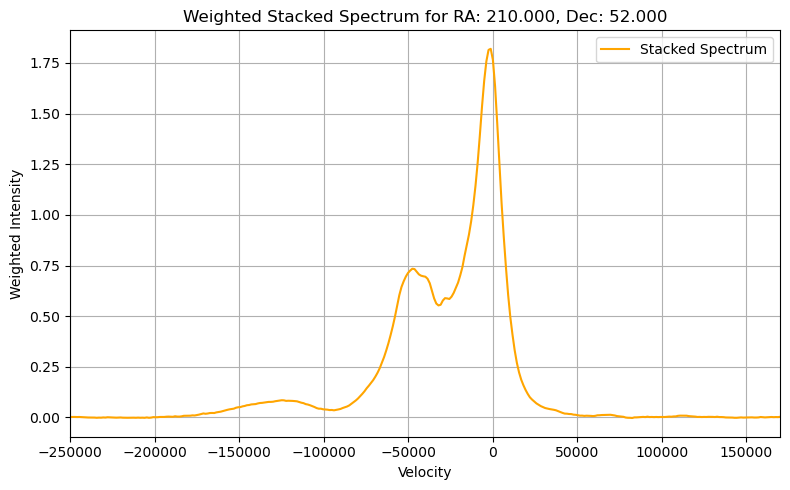

Pixels used in stack: 913991


In [5]:
# --- Example call ---

# Required inputs
target_ra = 210.0        # degrees
target_dec = 52.0        # degrees
beam_fwhm_deg = 20.4      # degrees

# Optional: your own comparison spectrum (velocity in m/s, intensity in K)
comparison_velocity = None    # e.g. 1000 * np.array([...])
comparison_intensity = None   # e.g. np.array([...])

velocity, weighted_spectrum, n_pixels = stack_hi_spectrum(
    target_ra=target_ra,
    target_dec=target_dec,
    beam_fwhm_deg=beam_fwhm_deg,
    strips_table_path="all_ra_strips2.fits",
    tan_dir="/home/edgeflame/Documents/internshiph1/TAN",
    min_weight=1e-5,
    comparison_velocity=comparison_velocity,
    comparison_intensity=comparison_intensity,
    comparison_label="Radio Telescope Data",
    plot=True,
    xlim=(-250000, 170000),
)

print("Pixels used in stack:", n_pixels)
